# Error analysis, prediction intervals and a headroom policy for the aggregate CPU forecast

Purpose: find where the submitted forecast (ARIMA with the hourly profile) fails, put an uncertainty band around it, and turn the band into a simple capacity rule.

- Inputs: `vm_cpu_readings.csv.gz` (`data-v1`). Only the first 110 timestamps (the training window) are used; the last 24 are never loaded.
- Code: the logic is in `src/cwfc/policy.py` (tested in `tests/test_policy.py`); the forecasts come from `models.py` and `predict.py`. This notebook only calls them.
- Outputs: `reports/figures/policy_*.png` and `reports/tables/policy_*.csv`.
- Run: from an environment where the project is installed (the conda `atomity` environment or the venv from the README), `jupyter nbconvert --to notebook --execute --inplace notebooks/03_policy.ipynb`. It takes about two minutes.
- Terms: pp is percentage points; a step is 5 minutes; an origin is the moment a forecast is issued; an error is actual minus forecast, so a positive error means the forecast was too low; high-load values are at or above the 80th percentile of the history at that origin; coverage is the share of actual values inside an interval; capacity is the forecast plus a margin; shortfall is demand above capacity and excess is capacity above demand.
- Calibration: a margin or interval may use only errors already known at the origin (a step's error is known once that step is observed), so the early origins cannot be checked.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cwfc import analysis as an
from cwfc import evaluate as ev
from cwfc import models, policy, predict
from cwfc.data import ACTIVE_VM_COUNT, AGGREGATE_CPU, HOLDOUT_HORIZON, build_targets, load_readings, split_holdout
from cwfc.features import future_timestamps

an.set_plot_style()
N_JOBS = -1  # use every core for the rolling-origin run; the results do not depend on it
REPORT_STEPS = (1, 6, 12, 24)  # forecast steps shown in the tables: 5, 30, 60 and 120 minutes ahead
INTERVAL_LEVELS = (0.8, 0.9)
COST_RATIOS = (1, 2, 5, 10, 20)  # cost of one unit of shortfall in units of idle capacity
EPISODE_MIN_STEPS = 6  # high-load runs of at least 30 minutes form the main episode, as in the EDA

## 1. The errors to analyse

What is checked: the rolling-origin forecasts of the submitted model (ARIMA with the hourly profile) and of the baseline on the training window, the same test as in `02_modeling.ipynb`. Every later section works on these errors.

In [2]:
train, _ = split_holdout(build_targets(load_readings()))
series = train[AGGREGATE_CPU]
hours = an.elapsed_hours(series.index)
result = ev.run_cv(series, {models.BASELINE_NAME: models.baseline_forecast, models.ARIMA_NAME: models.candidate_forecasters()[models.ARIMA_NAME]}, n_jobs=N_JOBS)
forecast = result.predictions[models.ARIMA_NAME]
errors = policy.forecast_errors(result, models.ARIMA_NAME)
runs = an.peak_periods(series, series.quantile(ev.HIGH_LOAD_QUANTILE))
long_runs = runs[runs["n_steps"] >= EPISODE_MIN_STEPS]
since_start = pd.Series(hours, index=series.index)
episode_hours = (since_start[long_runs["start"].min()], since_start[long_runs["end"].max()])
print(f"{len(result.origins)} origins with {errors.shape[1]} steps each, {errors.size} errors, about {(len(series) - result.origins[0]) / HOLDOUT_HORIZON:.1f} independent 24-step windows")
print(f"main high-load episode: hour {episode_hours[0]:.1f} to {episode_hours[1]:.1f}")
print(f"overall ARIMA bias (actual minus forecast): {errors.mean():.3f} pp, MAE: {np.abs(errors).mean():.3f} pp")

39 origins with 24 steps each, 936 errors, about 2.6 independent 24-step windows
main high-load episode: hour 4.4 to 6.0
overall ARIMA bias (actual minus forecast): -0.027 pp, MAE: 0.179 pp


**Finding.** The rolling-origin test gives 39 origins and 936 errors (24 steps each). The submitted model's average error is -0.027 pp and its MAE is 0.179 pp. The main high-load episode runs from hour 4.4 to 6.0.

**So what.** An average error close to zero can hide errors of opposite signs. The next section separates them by horizon, by position in the hour and by load.

## 2. Where and why the forecast fails

What is checked: how the ARIMA error changes with the forecast step, with the position in the hour, between high-load values and the rest, and which origins are the worst.

,ARIMA MAE,ARIMA bias,Baseline MAE
step,,,
1,0.082,0.020,0.198
6,0.195,0.045,0.228
12,0.196,-0.010,0.194
24,0.175,-0.155,0.166


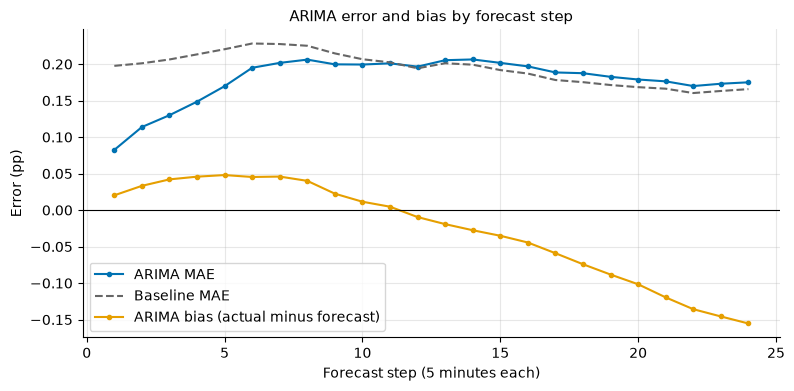

In [3]:
step_table = pd.DataFrame(
    {
        "ARIMA MAE": np.abs(errors).mean(axis=0),
        "ARIMA bias": errors.mean(axis=0),
        "Baseline MAE": ev.horizon_table(result)[models.BASELINE_NAME].to_numpy(),
    },
    index=pd.Index(np.arange(1, errors.shape[1] + 1), name="step"),
)
an.save_table(step_table.round(4), "policy_error_by_step")
display(step_table.loc[list(REPORT_STEPS)].round(3))
fig, ax = plt.subplots()
ax.plot(step_table.index, step_table["ARIMA MAE"], marker="o", markersize=3, label="ARIMA MAE")
ax.plot(step_table.index, step_table["Baseline MAE"], linestyle="--", color=an.PALETTE["grey"], label="Baseline MAE")
ax.plot(step_table.index, step_table["ARIMA bias"], marker="o", markersize=3, label="ARIMA bias (actual minus forecast)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Forecast step (5 minutes each)")
ax.set_ylabel("Error (pp)")
ax.set_title("ARIMA error and bias by forecast step")
ax.legend()
an.save_figure(fig, "policy_error_by_step")
plt.show()

**Finding.** The ARIMA MAE is 0.082 pp at step 1, 0.195 at step 6, 0.196 at step 12 and 0.175 at step 24. Its advantage over the baseline is large at step 1 (0.198 for the baseline), smaller at step 6 (0.228) and gone by step 12 (0.194). The bias is +0.020 pp at step 1 and +0.045 at step 6, near zero at step 12 (-0.010) and -0.155 at step 24.

**So what.** The latest value is worth using for about the next 30 minutes. Further out the model returns to the hourly profile, and at the end of the window it over-forecasts, probably because it carries a high recent level forward while the actual level falls back. For the second hour, rely on the forecast level plus the margin rule of section 4, not on the latest observation.

,values,MAE,bias
position,,,
0,78,0.133,0.005
1,78,0.152,-0.058
2,78,0.168,-0.078
3,78,0.197,-0.026
4,78,0.132,0.003
5,78,0.157,-0.017
6,78,0.193,-0.046
7,78,0.272,-0.023
8,78,0.204,0.049


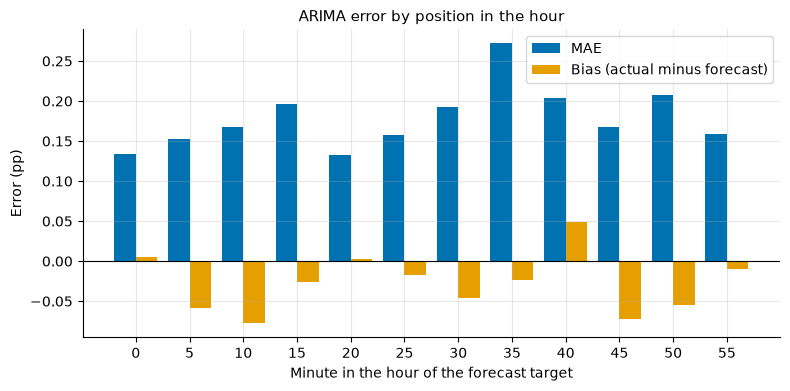

In [4]:
position_table = policy.error_by_position(result, models.ARIMA_NAME)
an.save_table(position_table.round(4), "policy_error_by_position")
display(position_table.round(3))
fig, ax = plt.subplots()
minutes = position_table.index * 5
ax.bar(minutes - 1, position_table["MAE"], width=2, label="MAE")
ax.bar(minutes + 1, position_table["bias"], width=2, label="Bias (actual minus forecast)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(minutes)
ax.set_xlabel("Minute in the hour of the forecast target")
ax.set_ylabel("Error (pp)")
ax.set_title("ARIMA error by position in the hour")
ax.legend()
an.save_figure(fig, "policy_error_by_position")
plt.show()

**Finding.** The MAE by position in the hour ranges from 0.132 pp (minute 20) to 0.272 pp (minute 35). The 20-minute slot, where the EDA found a recurring dip, has one of the lowest errors and almost no bias (0.003). The next largest errors are at minute 50 (0.208) and minute 40 (0.204). Every slot holds 78 values.

**So what.** The hourly profile does capture the recurring dip, so it is not a failure case. The worst slot is about twice as bad as the best, but with nine hours of data and overlapping windows the slot differences are indicative only, and no slot-specific rule is justified.

In [5]:
high = result.high_load
load_table = pd.DataFrame(
    {
        "values": [int(high.sum()), int((~high).sum())],
        "MAE": [np.abs(errors[high]).mean(), np.abs(errors[~high]).mean()],
        "bias": [errors[high].mean(), errors[~high].mean()],
    },
    index=["high-load values", "other values"],
)
an.save_table(load_table.round(4), "policy_error_by_load")
display(load_table.round(3))
worst = policy.worst_origins(result, models.ARIMA_NAME, count=5)
worst["hours at the first forecast step"] = (worst["first timestamp"] - series.index[0]) / 3600
worst = worst.drop(columns="first timestamp")
an.save_table(worst.round(4), "policy_worst_origins")
display(worst.round(3))

,values,MAE,bias
high-load values,302,0.238,0.223
other values,634,0.150,-0.146


,history points,MAE,bias,hours at the first forecast step
0,49,0.293,0.293,4.083
1,52,0.292,0.277,4.333
2,50,0.290,0.289,4.167
3,51,0.290,0.282,4.250
4,53,0.286,0.268,4.417


**Finding.** At the 302 high-load values the forecast is too low by 0.223 pp on average (MAE 0.238). At the other 634 values it is too high by 0.146 pp (MAE 0.150). The five worst origins all have 49 to 53 points of history, which is hours 4.1 to 4.4 at the first forecast step, with an MAE of 0.286 to 0.293 and a bias of +0.268 to +0.293.

**So what.** The two biases roughly cancel in the overall average (-0.027 pp), so the average hides the real problem: the model under-forecasts peaks and over-forecasts the rest. The worst failures are the origins just before the main episode starts at hour 4.4. A level shift that has not begun cannot be forecast from the past, and the model reacts only after the first high values appear. A margin that waits for a high level therefore cannot protect the first minutes of a peak, and this remains the residual risk.

## 3. Prediction intervals

What is checked: an interval around each forecast, at the 80% and 90% levels, from the earlier errors at the same step. Two constructions are compared. The signed version takes the lower and upper quantiles of the errors, so it also corrects for the forecast being too high or too low on average. The absolute-error version is the forecast plus and minus the quantile of the absolute errors, which does not care about the sign. Coverage is measured out of time, using only the errors known when each forecast was issued, and compared with the coverage measured on the same errors the quantiles came from (which is too good, because the quantiles have already seen those errors).

,nominal level,out-of-time coverage,values checked,same-sample coverage,mean width (pp)
"80% interval, absolute-error quantile",0.8,0.908,468.0,0.795,0.629
"80% interval, signed quantiles",0.8,0.457,468.0,NaN,0.439
"90% interval, absolute-error quantile",0.9,0.936,468.0,0.897,0.761
"90% interval, signed quantiles",0.9,0.517,468.0,NaN,0.525


0.8                         0.9                    
     checked coverage mean width checked coverage mean width
step                                                        
1         31    0.871      0.293      31    0.935      0.463
6         26    1.000      0.771      26    1.000      0.923
12        20    1.000      0.703      20    1.000      0.782
24         8    0.000      0.301       8    0.125      0.340

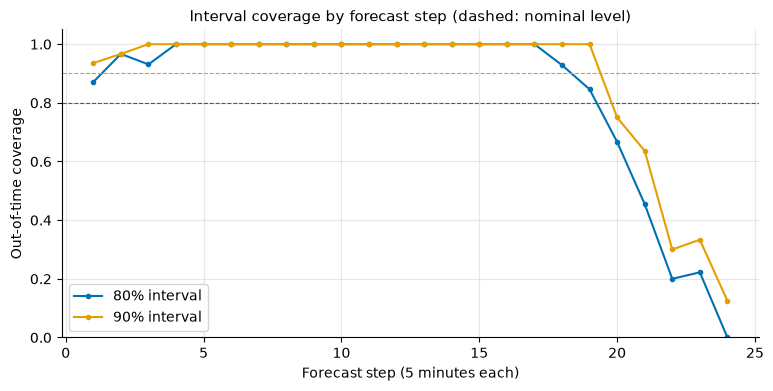

In [6]:
realised_abs = policy.realised_error_quantiles(errors, result.origins, INTERVAL_LEVELS, absolute=True)
all_abs = policy.final_error_quantiles(errors, INTERVAL_LEVELS, absolute=True)
signed_probabilities = sorted({p for level in INTERVAL_LEVELS for p in ((1 - level) / 2, (1 + level) / 2)})
realised_signed = policy.realised_error_quantiles(errors, result.origins, signed_probabilities)
rows, by_step = {}, {}
for i, level in enumerate(INTERVAL_LEVELS):
    lower, upper = -realised_abs[:, :, i], realised_abs[:, :, i]
    share, checked = policy.coverage(result.actual, forecast, lower, upper)
    same_share, _ = policy.coverage(result.actual, forecast, np.broadcast_to(-all_abs[:, i], errors.shape), np.broadcast_to(all_abs[:, i], errors.shape))
    rows[f"{level:.0%} interval, absolute-error quantile"] = {"nominal level": level, "out-of-time coverage": share, "values checked": checked, "same-sample coverage": same_share, "mean width (pp)": float(np.nanmean(upper - lower))}
    by_step[level] = policy.coverage_by_step(result.actual, forecast, lower, upper)
    low_s, high_s = signed_probabilities.index((1 - level) / 2), signed_probabilities.index((1 + level) / 2)
    signed_share, signed_checked = policy.coverage(result.actual, forecast, realised_signed[:, :, low_s], realised_signed[:, :, high_s])
    rows[f"{level:.0%} interval, signed quantiles"] = {"nominal level": level, "out-of-time coverage": signed_share, "values checked": signed_checked, "same-sample coverage": np.nan, "mean width (pp)": float(np.nanmean(realised_signed[:, :, high_s] - realised_signed[:, :, low_s]))}
coverage_table = pd.DataFrame(rows).T
an.save_table(coverage_table.round(4), "policy_interval_coverage")
display(coverage_table.round(3))
step_coverage = pd.concat(by_step, axis=1)
an.save_table(step_coverage.round(4), "policy_interval_coverage_by_step")
display(step_coverage.loc[list(REPORT_STEPS)].round(3))
fig, ax = plt.subplots()
for level, table in by_step.items():
    valid = table["checked"] > 0
    line = ax.plot(table.index[valid], table.loc[valid, "coverage"], marker="o", markersize=3, label=f"{level:.0%} interval")
    ax.axhline(level, linestyle="--", color=line[0].get_color(), linewidth=0.8)
ax.set_xlabel("Forecast step (5 minutes each)")
ax.set_ylabel("Out-of-time coverage")
ax.set_ylim(0, 1.05)
ax.set_title("Interval coverage by forecast step (dashed: nominal level)")
ax.legend()
an.save_figure(fig, "policy_interval_coverage")
plt.show()

**Finding.** The signed-quantile intervals cover only 45.7% (80% level) and 51.7% (90% level) of the 468 values that can be checked out of time. The absolute-error intervals cover 90.8% and 93.6%, above the nominal levels, with widths of 0.629 pp and 0.761 pp. On the errors they were calibrated on, the absolute-error intervals cover 79.5% and 89.7%, as expected. By step, coverage is 87.1% and 93.5% at step 1, 100% at steps 6 and 12, and 0% and 12.5% at step 24, where only 8 values can be checked.

**So what.** The signed intervals fail mainly because the sign of the error changes over the test (the forecast is too low at peaks and too high elsewhere, section 2), so quantiles learned earlier point the wrong way later. The absolute-error interval does not care about the sign and is wider than the nominal level asks, which is the safe direction for capacity planning. The same-sample figures look right but say little, because the quantiles have already seen those errors. At the end of the horizon only a few errors are known and the model's bias is changing, so the nominal level should not be trusted there. With about 2.6 independent windows these figures are rough: they show that the signed construction fails and the absolute one holds up, not an exact coverage.

## 4. Headroom policy

What is checked: a rule for the capacity to plan for, capacity = forecast + margin. The margin is a one-sided quantile of the earlier errors at the same step, so a higher quantile means more margin. Section 4.1 tries a margin that is always on. Section 4.2 adds a peak-risk trigger: the margin is added only when the mean of the latest 15 minutes (three observations) is at or above the 80th percentile of the history so far, that is, when the series is already running high. Everything is simulated on the rolling origins using only information known at each origin, and all options are compared on the same values.

How the setting is chosen: running short at a peak is the costly mistake, so the rule is a service-level target and not a guessed cost ratio. Among the options, take the one with the smallest mean margin whose share of high-load values above the planned capacity is at most 5%. The cost view (one unit of shortfall costs a stated number of units of idle capacity) is shown next to it, because the cost ratio is an assumption and the conclusion should be checked against it.

### 4.1 A margin that is always on

In [7]:
margin_probabilities = policy.MARGIN_PROBABILITIES
labels = ["no margin", *[f"quantile {p:.2f}" for p in margin_probabilities]]
quantiles = policy.realised_margins(errors, result.origins, margin_probabilities)
margins = np.stack([np.zeros(errors.shape), *[quantiles[:, :, k] for k in range(len(margin_probabilities))]])
curve = policy.headroom_curve(result.actual, forecast, margins, labels, high_load=result.high_load)
curve["cost at ratio 5"] = policy.provisioning_cost(curve, 5)
an.save_table(curve.round(4), "policy_headroom_curve")
print(f"values compared: {curve.attrs['values used']} of {errors.size}, of which {int((result.high_load & np.isfinite(margins).all(axis=0)).sum())} are high-load")
display(curve.round(3))

values compared: 468 of 936, of which 62 are high-load


,under-provisioned share,mean shortfall,mean excess,mean margin,high-load under-provisioned share,cost at ratio 5
no margin,0.120,0.012,0.132,0.000,0.645,0.192
quantile 0.50,0.043,0.003,0.271,0.148,0.210,0.284
quantile 0.60,0.026,0.002,0.321,0.200,0.161,0.331
quantile 0.70,0.015,0.001,0.371,0.250,0.113,0.375
quantile 0.80,0.006,0.001,0.425,0.305,0.048,0.428
quantile 0.85,0.004,0.000,0.458,0.338,0.032,0.459
quantile 0.90,0.002,0.000,0.498,0.378,0.016,0.498
quantile 0.95,0.000,0.000,0.555,0.436,0.000,0.555


**Finding.** Of the 936 errors, 468 have a margin to compare on, and 62 of those are high-load values. With no margin, 12.0% of all values and 64.5% of the high-load values exceed the planned capacity. A margin at quantile 0.8 brings the high-load share down to 4.8% with a mean margin of 0.305 pp, and quantile 0.9 to 1.6% with 0.378 pp. The mean idle capacity rises from 0.132 pp with no margin to 0.425 pp at quantile 0.8. At a cost ratio of 5 the cost is 0.192 with no margin and 0.428 at quantile 0.8.

**So what.** A margin that is always on protects peaks but pays for idle capacity at the many values that are not peaks, so on cost alone, with a shortfall ratio of 5, no margin is cheapest. The two views disagree, and the reason is that only a small part of the values are peaks. Only 62 high-load values come from one episode, so these shares are rough.

### 4.2 A margin that switches on at peak risk

In [8]:
trigger = policy.peak_risk_trigger(series.to_numpy(), result.origins)
print(f"peak-risk trigger on at {int(trigger.sum())} of {len(trigger)} origins")
trigger_quantiles = (0.8, 0.9, 0.95)
options = {"no margin": np.zeros(errors.shape)}
for p in trigger_quantiles:
    margin = quantiles[:, :, margin_probabilities.index(p)]
    options[f"always on, quantile {p}"] = margin
    options[f"trigger on, quantile {p}"] = policy.apply_trigger(margin, trigger)
policy_curve = policy.headroom_curve(result.actual, forecast, np.stack(list(options.values())), list(options), high_load=result.high_load)
for ratio in COST_RATIOS:
    policy_curve[f"cost at ratio {ratio}"] = policy.provisioning_cost(policy_curve, ratio)
an.save_table(policy_curve.round(4), "policy_comparison")
display(policy_curve.round(3))
trigger_options = {f"trigger on, quantile {p}": p for p in trigger_quantiles}
chosen = policy.choose_option(policy_curve.loc[list(trigger_options)])
chosen_probability = trigger_options[chosen]
print(f"chosen setting (smallest margin with at most {policy.HIGH_LOAD_TARGET_SHARE:.0%} of high-load values above capacity): {chosen}")

peak-risk trigger on at 17 of 39 origins


,under-provisioned share,mean shortfall,mean excess,mean margin,high-load under-provisioned share,cost at ratio 1,cost at ratio 2,cost at ratio 5,cost at ratio 10,cost at ratio 20
no margin,0.120,0.012,0.132,0.000,0.645,0.144,0.156,0.192,0.252,0.372
"always on, quantile 0.8",0.006,0.001,0.425,0.305,0.048,0.425,0.426,0.428,0.430,0.436
"trigger on, quantile 0.8",0.026,0.001,0.224,0.104,0.048,0.225,0.226,0.229,0.235,0.245
"always on, quantile 0.9",0.002,0.000,0.498,0.378,0.016,0.498,0.498,0.498,0.498,0.498
"trigger on, quantile 0.9",0.021,0.000,0.245,0.125,0.016,0.246,0.246,0.248,0.250,0.255
"always on, quantile 0.95",0.000,0.000,0.555,0.436,0.000,0.555,0.555,0.555,0.555,0.555
"trigger on, quantile 0.95",0.019,0.000,0.265,0.145,0.000,0.265,0.266,0.267,0.270,0.274


chosen setting (smallest margin with at most 5% of high-load values above capacity): trigger on, quantile 0.8


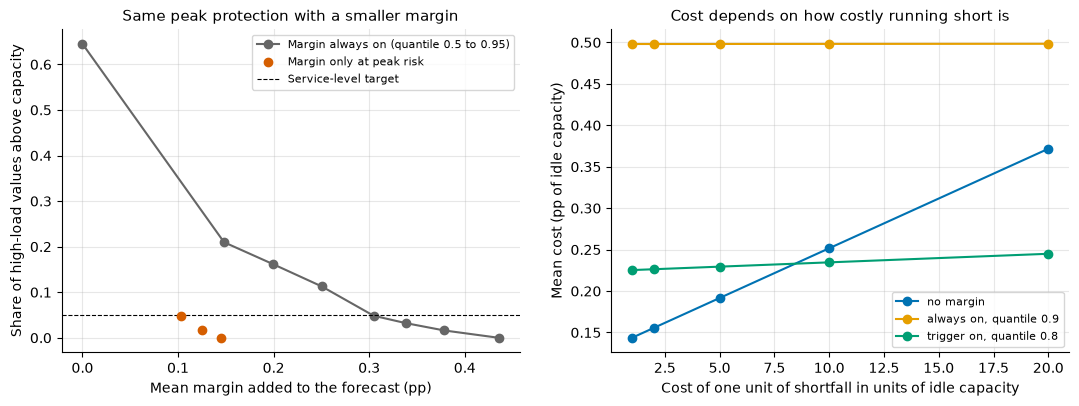

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(curve["mean margin"], curve["high-load under-provisioned share"], marker="o", color=an.PALETTE["grey"], label="Margin always on (quantile 0.5 to 0.95)")
triggered = policy_curve.loc[list(trigger_options)]
axes[0].scatter(triggered["mean margin"], triggered["high-load under-provisioned share"], color=an.PALETTE["red"], zorder=3, label="Margin only at peak risk")
axes[0].axhline(policy.HIGH_LOAD_TARGET_SHARE, linestyle="--", color="black", linewidth=0.8, label="Service-level target")
axes[0].set_xlabel("Mean margin added to the forecast (pp)")
axes[0].set_ylabel("Share of high-load values above capacity")
axes[0].set_title("Same peak protection with a smaller margin")
axes[0].legend(fontsize=8)
for name in ("no margin", "always on, quantile 0.9", chosen):
    axes[1].plot(COST_RATIOS, [policy_curve.loc[name, f"cost at ratio {ratio}"] for ratio in COST_RATIOS], marker="o", label=name)
axes[1].set_xlabel("Cost of one unit of shortfall in units of idle capacity")
axes[1].set_ylabel("Mean cost (pp of idle capacity)")
axes[1].set_title("Cost depends on how costly running short is")
axes[1].legend(fontsize=8)
an.save_figure(fig, "policy_tradeoff")
plt.show()

**Finding.** The trigger is on at 17 of 39 origins. At quantile 0.8 the margin only at peak risk leaves 4.8% of the high-load values above capacity, the same as the always-on margin, with a mean margin of 0.104 pp instead of 0.305 pp. Its cost is 0.229 at a ratio of 5, 0.235 at 10 and 0.245 at 20. With no margin the cost is 0.192, 0.252 and 0.372 at those ratios, and the always-on margin costs 0.428, 0.430 and 0.436. The setting chosen by the service-level target (smallest margin with at most 5% of high-load values above capacity) is the trigger with quantile 0.8. Quantile 0.9 lowers the high-load share to 1.6% for a mean margin of 0.125 pp.

**So what.** Switching the margin on only when the series is already running high keeps the peak protection and removes most of the idle capacity, and its cost hardly depends on the assumed cost ratio. No margin is cheaper when running short costs no more than about five times idle capacity (0.192 against 0.229), and the triggered margin is cheaper from a ratio of about 10 (0.235 against 0.252), so the choice depends on how costly a shortfall is. Quantile 0.8 meets the 5% target by a small step (4.8%); with only 62 high-load values the difference from quantile 0.9 is two values, so quantile 0.9 is the safer setting for 0.021 pp more margin on average.

### 4.3 The plan for the next two hours

peak-risk trigger at the end of the training window: off (latest mean 9.16% against an 80th percentile of 9.55%)


,forecast,lower 80%,lower 90%,upper 80%,upper 90%,capacity if the trigger is on,capacity now
timestamp,,,,,,,
33000,9.195,9.089,8.981,9.301,9.409,9.257,9.195
34500,9.212,8.930,8.795,9.495,9.630,9.453,9.212
36300,9.353,9.065,9.009,9.642,9.697,9.638,9.353
38100,9.306,9.059,8.982,9.553,9.630,9.342,9.306
39900,9.400,9.148,9.099,9.651,9.700,9.400,9.400


mean margin if the trigger were on: 0.152 pp on a mean forecast of 9.32%; widest 90% interval 0.84 pp


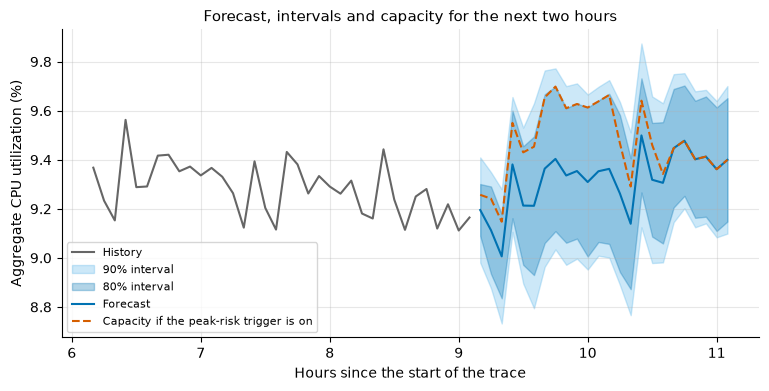

In [10]:
final_forecast, _ = predict.forecast_cpu(series, HOLDOUT_HORIZON)
future_stamps = future_timestamps(series.index[-1], HOLDOUT_HORIZON)
trigger_now = bool(policy.peak_risk_trigger(series.to_numpy(), [len(series)])[0])
plan = policy.capacity_plan(final_forecast, future_stamps, errors, level=0.9, probability=chosen_probability)
plan_80 = policy.capacity_plan(final_forecast, future_stamps, errors, level=0.8, probability=chosen_probability)
plan = plan.rename(columns={"lower": "lower 90%", "upper": "upper 90%", "capacity": "capacity if the trigger is on"})
plan.insert(1, "lower 80%", plan_80["lower"])
plan.insert(3, "upper 80%", plan_80["upper"])
plan["capacity now"] = policy.capacity_plan(final_forecast, future_stamps, errors, level=0.9, probability=chosen_probability, margin_active=trigger_now)["capacity"]
an.save_table(plan.round(4), "policy_capacity_plan")
print(f"peak-risk trigger at the end of the training window: {'on' if trigger_now else 'off'} (latest mean {series.iloc[-policy.TRIGGER_RECENT_STEPS:].mean():.2f}% against an 80th percentile of {series.quantile(ev.HIGH_LOAD_QUANTILE):.2f}%)")
display(plan.iloc[[0, 5, 11, 17, 23]].round(3))
print(f"mean margin if the trigger were on: {(plan['capacity if the trigger is on'] - plan['forecast']).mean():.3f} pp on a mean forecast of {plan['forecast'].mean():.2f}%; widest 90% interval {(plan['upper 90%'] - plan['lower 90%']).max():.2f} pp")
tail = slice(len(series) - predict.TAIL_STEPS, None)
plan_hours = hours[-1] + np.arange(1, HOLDOUT_HORIZON + 1) * (hours[1] - hours[0])
fig, ax = plt.subplots()
ax.plot(hours[tail], series.to_numpy()[tail], color=an.PALETTE["grey"], label="History")
ax.fill_between(plan_hours, plan["lower 90%"], plan["upper 90%"], color=an.PALETTE["sky"], alpha=0.3, label="90% interval")
ax.fill_between(plan_hours, plan["lower 80%"], plan["upper 80%"], color=an.PALETTE["blue"], alpha=0.3, label="80% interval")
ax.plot(plan_hours, plan["forecast"], color=an.PALETTE["blue"], label="Forecast")
ax.plot(plan_hours, plan["capacity if the trigger is on"], color=an.PALETTE["red"], linestyle="--", label="Capacity if the peak-risk trigger is on")
ax.set_xlabel("Hours since the start of the trace")
ax.set_ylabel("Aggregate CPU utilization (%)")
ax.set_title("Forecast, intervals and capacity for the next two hours")
ax.legend(fontsize=8)
an.save_figure(fig, "policy_forecast_bands")
plt.show()

**Finding.** At the end of the training window the peak-risk trigger is off: the latest mean is 9.16% against an 80th percentile of 9.55%. The plan is therefore the forecast itself, from 9.195% at the first step to 9.400% at the last, with a 90% interval that is at most 0.84 pp wide and reaches 9.700% at the last step. If the trigger were on, the capacity line would add 0.152 pp on average to a mean forecast of 9.32%.

**So what.** The next two hours look calm. The recommended action is to plan for the forecast, to check the mean of the latest three observations each time a new forecast is issued, and to switch to the higher capacity line as soon as that mean reaches the 80th percentile of the history. The interval is the range to expect, and it is wide enough that a single reading inside it is not a reason to act.

### 4.4 The VM count

In [11]:
count_result = ev.run_cv(train[ACTIVE_VM_COUNT].astype(float), {"Persistence": models.persistence})
count_errors = policy.forecast_errors(count_result, "Persistence")
print(f"active_vm_count: largest absolute rolling-origin error {np.abs(count_errors).max():.1f} VMs over {count_errors.size} errors; the training counts take {train[ACTIVE_VM_COUNT].nunique()} distinct value")

active_vm_count: largest absolute rolling-origin error 0.0 VMs over 936 errors; the training counts take 1 distinct value


**Finding.** The largest absolute rolling-origin error of the VM-count forecast is 0.0 VMs over 936 errors, and the training counts take one distinct value.

**So what.** The count forecast needs no margin and no interval: planned VM capacity equals the forecast, and the headroom reasoning applies to the CPU series. If the count ever varies in other data, the same error-quantile method applies to it.

### Summary of findings

1. The forecast is useful for about 30 minutes (section 2, `policy_error_by_step`). The ARIMA MAE is 0.082 pp at step 1, 0.195 at step 6 and 0.196 at step 12, and the advantage over the baseline is gone by step 12. At step 24 the bias is -0.155 pp: the model over-forecasts at the end of the window.
2. The errors have opposite signs (section 2, `policy_error_by_load`). The forecast is too low by 0.223 pp at the 302 high-load values and too high by 0.146 pp at the other 634, so the overall bias of -0.027 pp hides both.
3. The worst failures are the origins just before the main episode (section 2, `policy_worst_origins`): histories of 49 to 53 points, an MAE of 0.286 to 0.293 pp and a bias of +0.268 to +0.293 pp. A level shift that has not started cannot be forecast.
4. The recurring 20-minute dip is handled (section 2, `policy_error_by_position`): MAE 0.132 pp and bias 0.003 at that slot, against 0.272 at the worst slot (minute 35).
5. Intervals built from the sign of earlier errors fail out of time: 45.7% and 51.7% coverage at the 80% and 90% levels. Intervals from the absolute errors cover 90.8% and 93.6% and are 0.629 and 0.761 pp wide (section 3, `policy_interval_coverage`). At step 24 only 8 values can be checked and they are mostly outside.
6. Without a margin, 64.5% of the high-load values exceed the planned capacity. An always-on margin at quantile 0.8 cuts this to 4.8% but adds 0.305 pp on average and costs 0.428 at a ratio of 5, against 0.192 with no margin (section 4.1, `policy_headroom_curve`).
7. A margin that switches on at peak risk keeps the protection at a mean margin of 0.104 pp and a cost of 0.229 to 0.245 across ratios 5 to 20, against 0.192 to 0.372 with no margin (section 4.2, `policy_comparison`, `policy_tradeoff`). No margin is cheaper at a ratio of 5 and the triggered margin from about 10.
8. For the next two hours the trigger is off and the plan is the forecast, 9.195% to 9.400%, with a 90% interval up to 0.84 pp wide (section 4.3, `policy_capacity_plan`, `policy_forecast_bands`).
9. The VM count has zero error, so it needs no margin (section 4.4).

### Recommended policy

1. Plan capacity at the forecast, and report it with the absolute-error interval (the forecast plus and minus the 80% or 90% quantile of the earlier absolute errors at the same step).
2. Each time a forecast is issued, compare the mean of the latest three observations (15 minutes) with the 80th percentile of the history so far. While it is at or above that level, plan capacity at the forecast plus the 80% quantile of the earlier errors at each step, never below the forecast.
3. Use the 90% quantile instead of the 80% quantile when the service-level target is stricter than 5% of high-load values above capacity (1.6% in this test).
4. Recompute the quantiles as new errors become known.

### Decisions carried forward

- The submitted CPU forecaster stays ARIMA(1,0,0) with the hourly profile; the margin and the interval are calculated from its rolling-origin errors.
- The margin setting is chosen by a service-level target, not by a cost ratio; the cost view is reported as a check and shows a break-even between ratios of 5 and 10.
- The interval uses absolute errors, and the margin is never negative.
- The report quotes these numbers as a rough guide, not as exact coverage.

### Limitations

- There are about 2.6 independent 24-step windows and one main high-load episode, so only 62 of the compared values are high-load and every share is rough.
- Calibration needs errors that are already known, so only 468 of the 936 errors can be compared, and the first origins have nothing to calibrate on.
- The start of a level shift cannot be protected: the trigger fires only once the series is already high.
- The setting of the margin quantile and the trigger window were chosen on the same rolling origins that evaluate them, so the results are mildly optimistic.
- The cost ratio is an assumption, not a measurement.
- At the last steps only a few errors are known, so the interval there is the least reliable.